## 1. Imports and reproducibility
We set random seeds for repeatable sampling/visualization. Model training will need additional seed and deterministic-backend settings.

In [1]:
import os
import random
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    

Python: 3.9.7
PyTorch: 2.8.0+cpu
CUDA available: False


## 2. Configuration and dataset loading
CIFAR images are already 32×32 RGB, so no resize operation is required. We first load the raw dataset without normalization so that raw examples and original pixel ranges can be inspected.

In [2]:
DATA_DIR = "./data"
DOWNLOAD = True  # Set False if the dataset is already present locally.
BATCH_SIZE = 128

# CIFAR-100 fine-label names are supplied by torchvision.
raw_transform = transforms.ToTensor()  # Converts uint8 pixels [0,255] to float tensors [0,1].

train_raw = datasets.CIFAR100(
    root=DATA_DIR, train=True, download=DOWNLOAD, transform=raw_transform
)
test_raw = datasets.CIFAR100(
    root=DATA_DIR, train=False, download=DOWNLOAD, transform=raw_transform
)

class_names = train_raw.classes
num_classes = len(class_names)

print(f"Train samples: {len(train_raw):,}")
print(f"Test samples:  {len(test_raw):,}")
print(f"Number of classes: {num_classes}")
print("Image tensor shape (C,H,W):", train_raw[0][0].shape)
print("First label/name:", train_raw[0][1], class_names[train_raw[0][1]])

100.0%


Train samples: 50,000
Test samples:  10,000
Number of classes: 100
Image tensor shape (C,H,W): torch.Size([3, 32, 32])
First label/name: 19 cattle


## 3. Validate dataset dimensions, labels, and pixel range
These checks make assumptions explicit and catch common data-loading problems early.

In [3]:
assert len(train_raw) == 50_000, "Unexpected CIFAR-100 training split size."
assert len(test_raw) == 10_000, "Unexpected CIFAR-100 test split size."
assert num_classes == 100, "Expected 100 fine classes for CIFAR-100."

sample_tensor, sample_label = train_raw[0]
assert tuple(sample_tensor.shape) == (3, 32, 32), "Expected 3-channel 32x32 image."
assert 0 <= int(sample_label) < num_classes, "Label outside expected class range."
assert float(sample_tensor.min()) >= 0.0 and float(sample_tensor.max()) <= 1.0

print("All basic shape, label, and pixel-range checks passed.")
print("Pixel range of first tensor:", float(sample_tensor.min()), "to", float(sample_tensor.max()))

All basic shape, label, and pixel-range checks passed.
Pixel range of first tensor: 0.003921568859368563 to 1.0


## 4. Raw image examples
The grid below uses real samples from the loaded dataset. The tensor is changed from channel-first to channel-last only for plotting; no pixel content is altered.

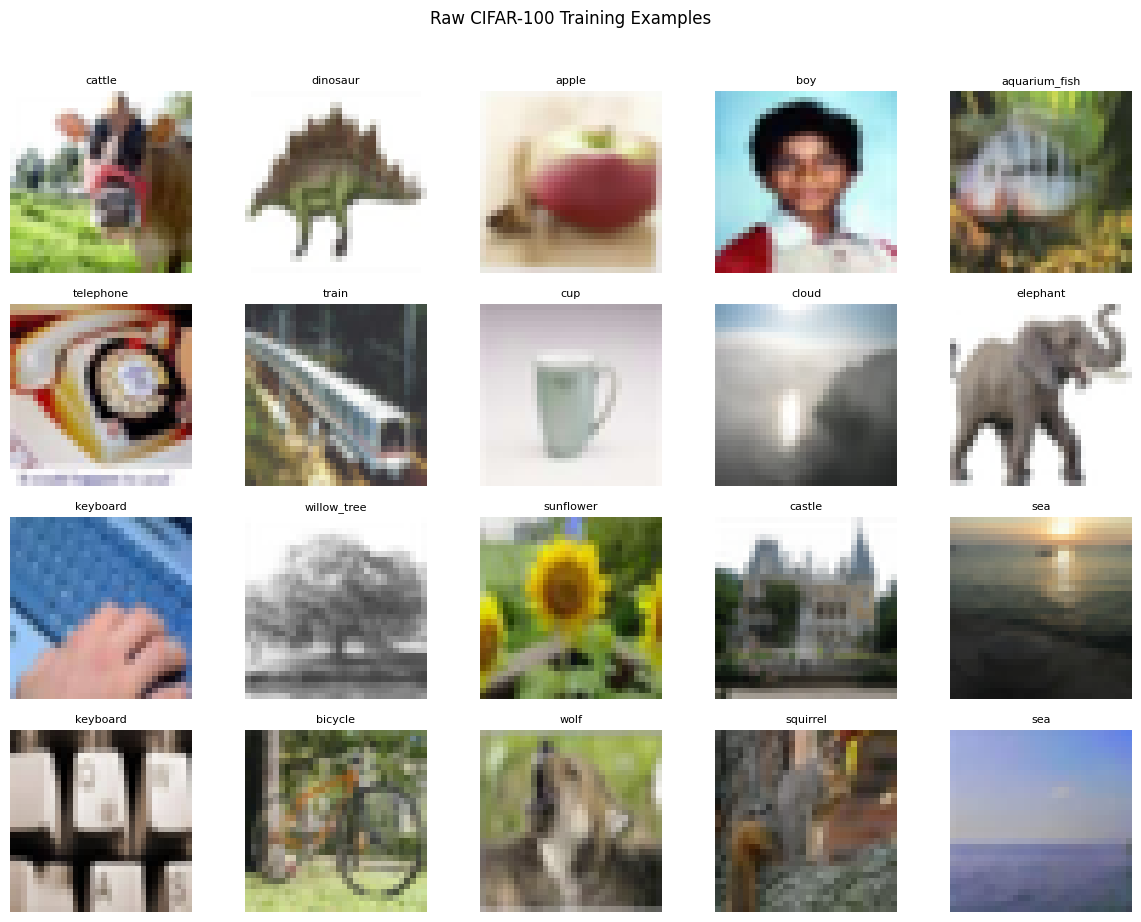

In [4]:
fig, axes = plt.subplots(4, 5, figsize=(12, 9))
for ax, idx in zip(axes.flat, range(20)):
    image, label = train_raw[idx]
    ax.imshow(image.permute(1, 2, 0).numpy())
    ax.set_title(class_names[label], fontsize=8)
    ax.axis("off")
plt.suptitle("Raw CIFAR-100 Training Examples", y=1.02)
plt.tight_layout()
plt.show()

## 5. Class distribution and split statistics
The official CIFAR-100 split is balanced by class count: 500 training and 100 test images per class. The code below verifies this against the actual labels instead of relying only on the documented design.

,class_id,class_name,train_count,test_count
0,0,apple,500,100
1,1,aquarium_fish,500,100
2,2,baby,500,100
3,3,bear,500,100
4,4,beaver,500,100
5,5,bed,500,100
6,6,bee,500,100
7,7,beetle,500,100
8,8,bicycle,500,100
9,9,bottle,500,100


Training counts min/max: 500 500
Test counts min/max: 100 100
Missing training classes: 0
Missing test classes: 0


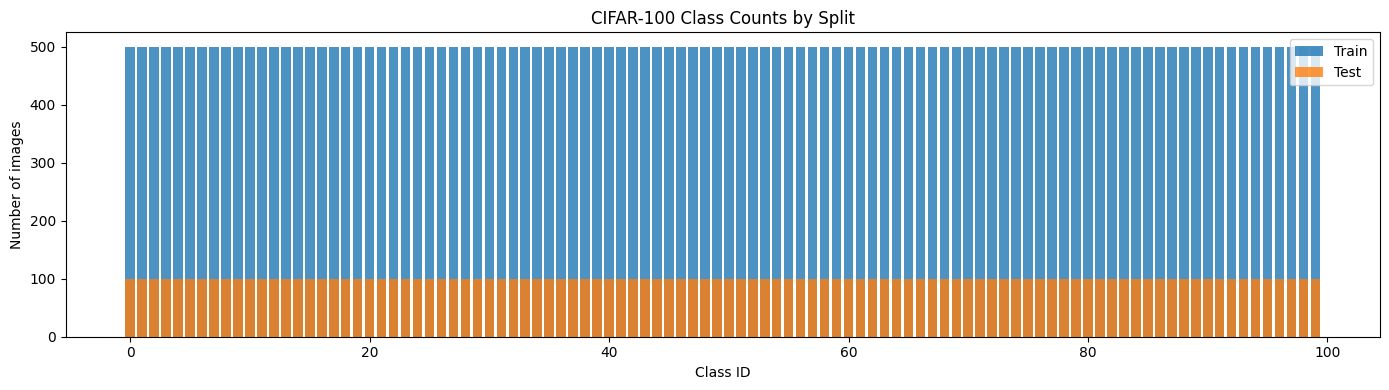

In [5]:
train_targets = np.asarray(train_raw.targets)
test_targets = np.asarray(test_raw.targets)
train_counts = np.bincount(train_targets, minlength=num_classes)
test_counts = np.bincount(test_targets, minlength=num_classes)

class_summary = pd.DataFrame({
    "class_id": np.arange(num_classes),
    "class_name": class_names,
    "train_count": train_counts,
    "test_count": test_counts,
})
display(class_summary.head(10))
print("Training counts min/max:", train_counts.min(), train_counts.max())
print("Test counts min/max:", test_counts.min(), test_counts.max())
print("Missing training classes:", int((train_counts == 0).sum()))
print("Missing test classes:", int((test_counts == 0).sum()))

fig, ax = plt.subplots(figsize=(14, 4))
ax.bar(np.arange(num_classes), train_counts, label="Train", alpha=0.8)
ax.bar(np.arange(num_classes), test_counts, label="Test", alpha=0.8)
ax.set_xlabel("Class ID")
ax.set_ylabel("Number of images")
ax.set_title("CIFAR-100 Class Counts by Split")
ax.legend()
plt.tight_layout()
plt.show()

## 6. Check raw array metadata and possible anomalies
The standard torchvision dataset stores images as an array and labels as integers. These checks verify dimensions, dtype, label range, and duplicates at the image-array level. Duplicate detection can be memory-intensive for large datasets, so it is optional.

In [6]:
raw_array = train_raw.data  # NumPy array, normally (50000, 32, 32, 3), uint8
print("Raw image array shape:", raw_array.shape)
print("Raw image dtype:", raw_array.dtype)
print("Raw pixel min/max:", int(raw_array.min()), int(raw_array.max()))
print("Any non-finite pixel values:", bool(np.isnan(raw_array).any()))

assert raw_array.shape == (50_000, 32, 32, 3)
assert raw_array.dtype == np.uint8
assert int(raw_array.min()) >= 0 and int(raw_array.max()) <= 255
assert np.isfinite(raw_array).all()

# Optional exact duplicate check on raw training images. Uncomment if desired.
# unique_images = np.unique(raw_array.reshape(len(raw_array), -1), axis=0).shape[0]
# print("Exact unique training images:", unique_images)
# print("Exact duplicate image count:", len(raw_array) - unique_images)

Raw image array shape: (50000, 32, 32, 3)
Raw image dtype: uint8
Raw pixel min/max: 0 255
Any non-finite pixel values: False


## 7. Define the normalized preprocessing pipeline
Normalization uses channel-wise mean and standard deviation commonly used for CIFAR-100. Training augmentation is intentionally configurable and disabled for the baseline EDA loader. When training the final model, any augmentation must be applied to training images only; the test set must remain deterministic.

In [7]:
CIFAR100_MEAN = (0.5071, 0.4867, 0.4408)
CIFAR100_STD  = (0.2675, 0.2565, 0.2761)

USE_TRAIN_AUGMENTATION = False

if USE_TRAIN_AUGMENTATION:
    train_transform = transforms.Compose([
        transforms.RandomCrop(32, padding=4),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize(CIFAR100_MEAN, CIFAR100_STD),
    ])
else:
    train_transform = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize(CIFAR100_MEAN, CIFAR100_STD),
    ])

test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(CIFAR100_MEAN, CIFAR100_STD),
])

train_dataset = datasets.CIFAR100(
    root=DATA_DIR, train=True, download=DOWNLOAD, transform=train_transform
)
test_dataset = datasets.CIFAR100(
    root=DATA_DIR, train=False, download=DOWNLOAD, transform=test_transform
)

print("Normalized train sample shape:", tuple(train_dataset[0][0].shape))
print("Normalized test sample shape:", tuple(test_dataset[0][0].shape))

Normalized train sample shape: (3, 32, 32)
Normalized test sample shape: (3, 32, 32)


## 8. Inspect a normalized batch
After standardization, values can be negative or greater than one. This is expected and is not a data error. The normalization is applied channel-wise.

In [8]:
train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=0, pin_memory=torch.cuda.is_available()
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=0, pin_memory=torch.cuda.is_available()
)

images, labels = next(iter(train_loader))
print("Batch image shape:", tuple(images.shape))  # (batch, 3, 32, 32)
print("Batch label shape:", tuple(labels.shape))
print("Normalized batch min/max:", float(images.min()), float(images.max()))
print("Batch labels min/max:", int(labels.min()), int(labels.max()))

Batch image shape: (128, 3, 32, 32)
Batch label shape: (128,)
Normalized batch min/max: -1.8974658250808716 2.025352954864502
Batch labels min/max: 0 99


## 9. Optional CIFAR-10 comparison dataset
CIFAR-10 is part of the proposed follow-up experiment. This cell loads it only if enabled, so users can avoid an extra download during the primary CIFAR-100 pipeline run.

In [9]:
LOAD_CIFAR10 = False  # Change to True when ready to inspect the additional dataset.

if LOAD_CIFAR10:
    cifar10_train = datasets.CIFAR10(
        root=DATA_DIR, train=True, download=DOWNLOAD, transform=transforms.ToTensor()
    )
    cifar10_test = datasets.CIFAR10(
        root=DATA_DIR, train=False, download=DOWNLOAD, transform=transforms.ToTensor()
    )
    print("CIFAR-10 train/test:", len(cifar10_train), len(cifar10_test))
    print("CIFAR-10 classes:", len(cifar10_train.classes), cifar10_train.classes)
    assert len(cifar10_train.classes) == 10

## 10. EDA summary and hand-off to model training

- **Dataset:** CIFAR-100, 50,000 train and 10,000 test RGB images, 100 classes.
- **Balance:** expected 500 train and 100 test images per class; verified by the class-count code above.
- **Data quality checks:** dimensions, dtype, pixel range, finite values, and label range.
- **Preprocessing:** tensor conversion and channel-wise normalization; optional random crop and horizontal flip for training only.
- **Metrics for later experiments:** top-1 test accuracy as the primary metric; per-class accuracy/confusion matrix as diagnostics; training and KD losses tracked but interpreted alongside accuracy.
- **Next stage:** implement ResNet-56 teacher and ResNet-20 student; compare vanilla KD against logit-standardized KD under matched training settings and seeds. This notebook intentionally stops before model training.